
# **SAR Flood Detection System - Complete Pipeline with Upload Interface**

In [ ]:
!pip install rasterio numpy scipy matplotlib tqdm torch scikit-learn flask pyngrok nest-asyncio werkzeug -q

print("Dependencies installed successfully")

Dependencies installed successfully


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import scipy.ndimage as ndimage
import rasterio
from rasterio.windows import Window
import zipfile
import tempfile
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
TILE_SIZE = 256
STRIDE = 128
IMAGE_HEIGHT = 3000
IMAGE_WIDTH = 3000
NUM_EPOCHS = 20
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

print(f"Configuration:")
print(f"  Tile size: {TILE_SIZE}x{TILE_SIZE}")
print(f"  Stride: {STRIDE}")
print(f"  Image size: {IMAGE_HEIGHT}x{IMAGE_WIDTH}")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Learning rate: {LEARNING_RATE}")

Configuration:
  Tile size: 256x256
  Stride: 128
  Image size: 3000x3000
  Epochs: 20
  Batch size: 16
  Learning rate: 0.001


In [ ]:
def generate_synthetic_sar_data(height=3000, width=3000):
    np.random.seed(42)

    vv_background = np.random.uniform(-20, -8, (height, width))
    vh_background = np.random.uniform(-22, -10, (height, width))

    y, x = np.ogrid[:height, :width]
    center_y, center_x = height//2, width//2

    river1 = np.exp(-((x - center_x)**2 + (y - center_y)**2) / (2 * (400)**2)) * 12
    river2 = np.exp(-((x - center_x-200)**2 + (y - center_y+150)**2) / (2 * (250)**2)) * 10
    urban = np.exp(-((x - center_x+300)**2 + (y - center_y-200)**2) / (2 * (150)**2)) * 8

    vv_image = vv_background + river1 + river2 + urban
    vh_image = vh_background + river1 * 0.8 + river2 * 0.7 + urban * 0.5

    vv_image = np.clip(vv_image, -25, -2)
    vh_image = np.clip(vh_image, -25, -2)

    flood_mask = (vv_image < -14).astype(np.float32)
    from scipy.ndimage import binary_dilation, binary_erosion
    flood_mask = binary_dilation(flood_mask, iterations=3)
    flood_mask = binary_erosion(flood_mask, iterations=2)
    noise = np.random.rand(*flood_mask.shape) < 0.03
    flood_mask = np.logical_xor(flood_mask, noise).astype(np.float32)

    return vv_image.astype(np.float32), vh_image.astype(np.float32), flood_mask.astype(np.float32)

print("Synthetic data generation function defined")
print("This will be used if no uploaded file is provided")

Synthetic data generation function defined
This will be used if no uploaded file is provided


In [ ]:
def lee_filter(image, kernel_size=5):
    """
    Lee speckle filter for SAR images
    Reduces noise while preserving edges
    """
    mean = ndimage.uniform_filter(image, size=kernel_size)
    mean_sq = ndimage.uniform_filter(image ** 2, size=kernel_size)
    local_variance = np.maximum(mean_sq - mean ** 2, 0)
    noise_variance = np.mean(local_variance)
    weighting = local_variance / (local_variance + noise_variance + 1e-10)
    filtered = mean + weighting * (image - mean)
    return filtered.astype(np.float32)

print("Lee filter function defined")

Lee filter function defined


In [ ]:
def extract_tiles(vv_array, vh_array, mask_array, tile_size=256, stride=128):
    """
    Extract overlapping tiles from SAR images
    Returns: tiles array [N, 2, H, W], masks array [N, 1, H, W], coordinates list
    """
    H, W = vv_array.shape
    tiles = []
    masks = []
    coords = []

    rows = range(0, H - tile_size + 1, stride)
    cols = range(0, W - tile_size + 1, stride)

    print(f"Extracting tiles from {H}x{W} image...")
    total_tiles = len(rows) * len(cols)

    for r in rows:
        for c in cols:
            vv_tile = vv_array[r:r+tile_size, c:c+tile_size]
            vh_tile = vh_array[r:r+tile_size, c:c+tile_size]
            mask_tile = mask_array[r:r+tile_size, c:c+tile_size]

            valid_ratio = np.mean(vv_tile > -29.0)
            if valid_ratio < 0.3:
                continue

            tile = np.stack([vv_tile, vh_tile], axis=0)
            tiles.append(tile)
            masks.append(mask_tile)
            coords.append((r, c))

    tiles_array = np.array(tiles, dtype=np.float32)
    masks_array = np.array(masks, dtype=np.float32).reshape(-1, 1, tile_size, tile_size)

    print(f"Extracted {len(tiles)} valid tiles from {total_tiles} candidates")
    return tiles_array, masks_array, coords

print("Tile extraction function defined")

Tile extraction function defined


In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=2, out_channels=1):
        super().__init__()

        self.encoder1 = DoubleConv(in_channels, 64)
        self.encoder2 = DoubleConv(64, 128)
        self.encoder3 = DoubleConv(128, 256)
        self.encoder4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512, 1024)

        self.upconv1 = nn.ConvTranspose2d(1024, 512, 2, 2)
        self.decoder1 = DoubleConv(1024, 512)

        self.upconv2 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.decoder2 = DoubleConv(512, 256)

        self.upconv3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.decoder3 = DoubleConv(256, 128)

        self.upconv4 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.decoder4 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, out_channels, 1)

    def forward(self, x):
        e1 = self.encoder1(x)
        p1 = self.pool(e1)

        e2 = self.encoder2(p1)
        p2 = self.pool(e2)

        e3 = self.encoder3(p2)
        p3 = self.pool(e3)

        e4 = self.encoder4(p3)
        p4 = self.pool(e4)

        b = self.bottleneck(p4)

        d1 = self.upconv1(b)
        d1 = torch.cat([e4, d1], dim=1)
        d1 = self.decoder1(d1)

        d2 = self.upconv2(d1)
        d2 = torch.cat([e3, d2], dim=1)
        d2 = self.decoder2(d2)

        d3 = self.upconv3(d2)
        d3 = torch.cat([e2, d3], dim=1)
        d3 = self.decoder3(d3)

        d4 = self.upconv4(d3)
        d4 = torch.cat([e1, d4], dim=1)
        d4 = self.decoder4(d4)

        return torch.sigmoid(self.final(d4))

print("U-Net model architecture defined")

U-Net model architecture defined


In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, prediction, target):
        prediction = prediction.view(-1)
        target = target.view(-1)
        intersection = (prediction * target).sum()
        dice = (2. * intersection + self.smooth) / (prediction.sum() + target.sum() + self.smooth)
        return 1 - dice

def calculate_iou(prediction, target, threshold=0.5):
    prediction = (prediction > threshold).float()
    intersection = (prediction * target).sum()
    union = (prediction + target).clamp(0, 1).sum()
    iou = (intersection + 1e-6) / (union + 1e-6)
    return iou.item()

print("Dice loss and IoU metrics defined")

Dice loss and IoU metrics defined


In [ ]:
class FloodDataset(Dataset):
    def __init__(self, images, masks):
        self.images = torch.from_numpy(images).float()
        self.masks = torch.from_numpy(masks).float()

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.masks[idx]

print("Dataset class defined")

Dataset class defined


Generating synthetic training data...
VV image - shape: (3000, 3000), range: [-20.00, -2.00]
VH image - shape: (3000, 3000), range: [-22.00, -2.00]
Flood mask - flood pixels: 7634877 (84.83%)


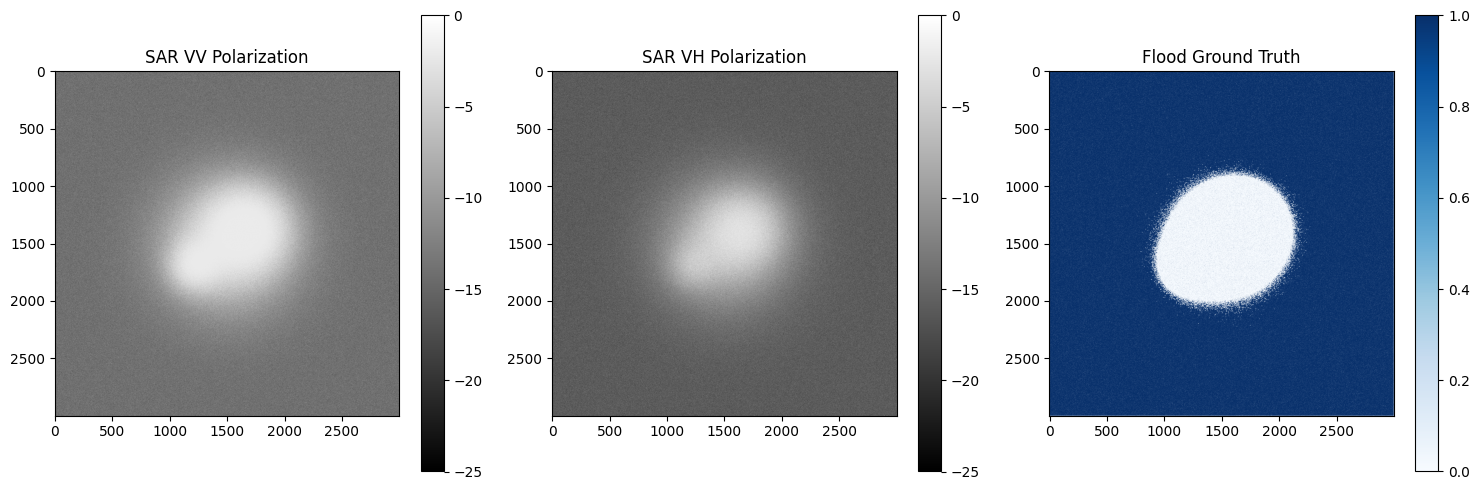

In [ ]:
print("Generating synthetic training data...")
vv_image, vh_image, flood_mask = generate_synthetic_sar_data(IMAGE_HEIGHT, IMAGE_WIDTH)

print(f"VV image - shape: {vv_image.shape}, range: [{vv_image.min():.2f}, {vv_image.max():.2f}]")
print(f"VH image - shape: {vh_image.shape}, range: [{vh_image.min():.2f}, {vh_image.max():.2f}]")
print(f"Flood mask - flood pixels: {flood_mask.sum():.0f} ({flood_mask.mean()*100:.2f}%)")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(vv_image, cmap='gray', vmin=-25, vmax=0)
plt.title("SAR VV Polarization")
plt.colorbar()
plt.subplot(1, 3, 2)
plt.imshow(vh_image, cmap='gray', vmin=-25, vmax=0)
plt.title("SAR VH Polarization")
plt.colorbar()
plt.subplot(1, 3, 3)
plt.imshow(flood_mask, cmap='Blues')
plt.title("Flood Ground Truth")
plt.colorbar()
plt.tight_layout()
plt.show()

Applying Lee speckle filter...


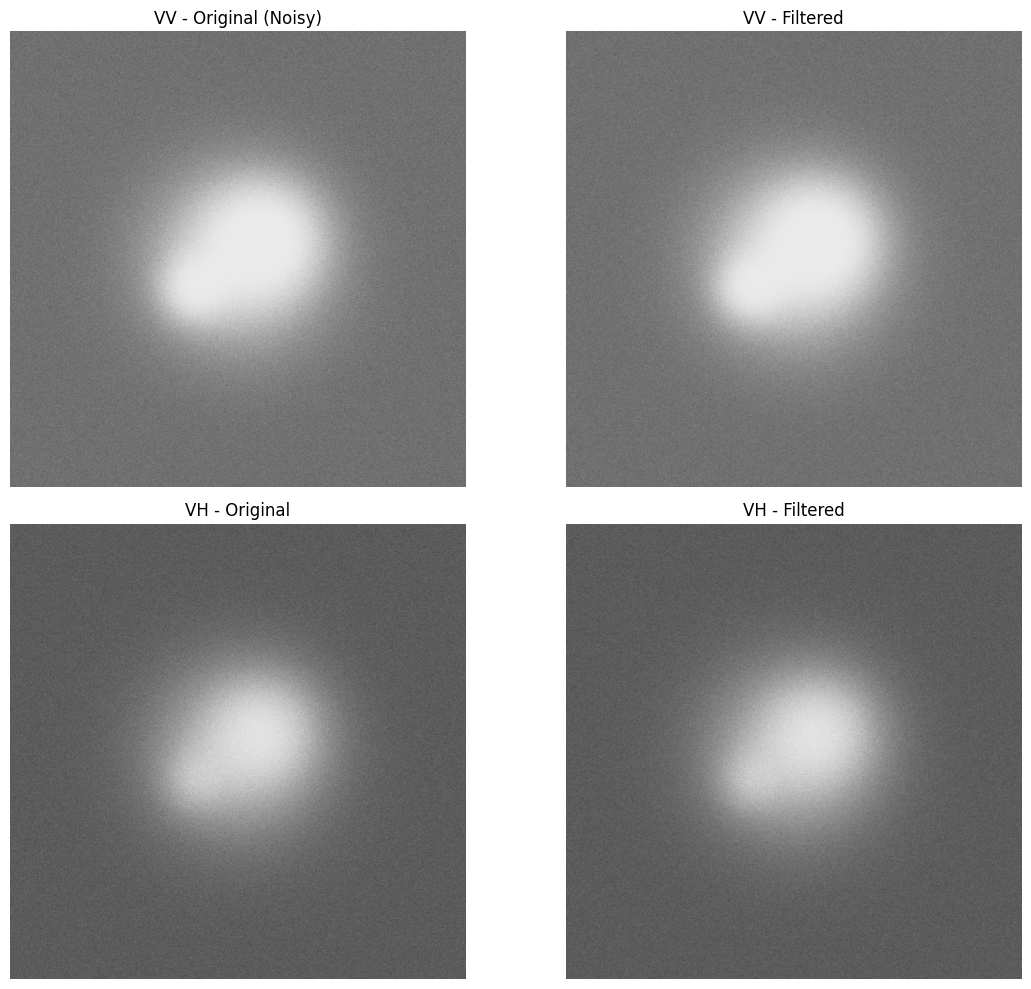

In [ ]:
print("Applying Lee speckle filter...")
vv_filtered = lee_filter(vv_image, kernel_size=5)
vh_filtered = lee_filter(vh_image, kernel_size=5)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes[0, 0].imshow(vv_image, cmap='gray', vmin=-25, vmax=0)
axes[0, 0].set_title("VV - Original (Noisy)")
axes[0, 0].axis('off')
axes[0, 1].imshow(vv_filtered, cmap='gray', vmin=-25, vmax=0)
axes[0, 1].set_title("VV - Filtered")
axes[0, 1].axis('off')
axes[1, 0].imshow(vh_image, cmap='gray', vmin=-25, vmax=0)
axes[1, 0].set_title("VH - Original")
axes[1, 0].axis('off')
axes[1, 1].imshow(vh_filtered, cmap='gray', vmin=-25, vmax=0)
axes[1, 1].set_title("VH - Filtered")
axes[1, 1].axis('off')
plt.tight_layout()
plt.show()

Extracting tiles from 3000x3000 image...
Extracted 484 valid tiles from 484 candidates

Dataset summary:
  Total tiles: 484
  Tiles containing water: 484 (100.0%)


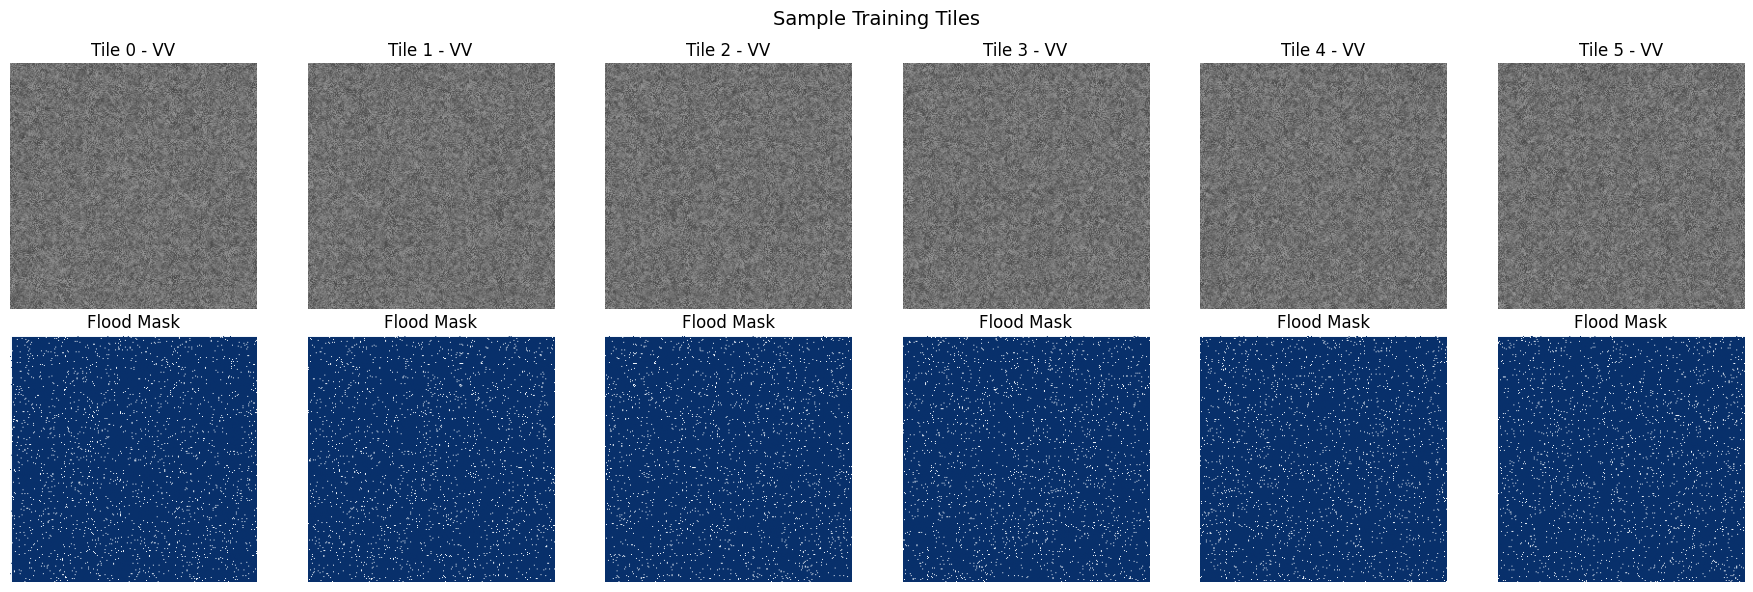

In [ ]:
tiles, masks, coords = extract_tiles(vv_filtered, vh_filtered, flood_mask, TILE_SIZE, STRIDE)

water_percentage = masks.mean(axis=(1, 2, 3))
water_indices = np.where(water_percentage > 0.01)[0]

if len(water_indices) < 50:
    water_indices = np.where(water_percentage > 0.001)[0]

tiles_balanced = tiles[water_indices]
masks_balanced = masks[water_indices]

print(f"\nDataset summary:")
print(f"  Total tiles: {len(tiles)}")
print(f"  Tiles containing water: {len(tiles_balanced)} ({len(tiles_balanced)/len(tiles)*100:.1f}%)")

sample_count = min(6, len(tiles_balanced))
fig, axes = plt.subplots(2, sample_count, figsize=(18, 6))
for i in range(sample_count):
    axes[0, i].imshow(tiles_balanced[i, 0], cmap='gray', vmin=-25, vmax=0)
    axes[0, i].set_title(f"Tile {i} - VV")
    axes[0, i].axis('off')
    axes[1, i].imshow(masks_balanced[i, 0], cmap='Blues')
    axes[1, i].set_title(f"Flood Mask")
    axes[1, i].axis('off')
plt.suptitle("Sample Training Tiles", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    tiles_balanced, masks_balanced, test_size=0.2, random_state=42, stratify=(masks_balanced.mean(axis=(1,2,3)) > 0.05)
)

train_dataset = FloodDataset(X_train, y_train)
val_dataset = FloodDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Training samples: 387
Validation samples: 97
Training batches: 25
Validation batches: 7


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet(in_channels=2, out_channels=1).to(device)
criterion = DiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

model_params = sum(p.numel() for p in model.parameters())
print(f"Device: {device}")
print(f"Model parameters: {model_params:,}")
print(f"Optimizer: Adam (lr={LEARNING_RATE})")
print(f"Scheduler: ReduceLROnPlateau (patience=3)")

Device: cuda
Model parameters: 31,037,057
Optimizer: Adam (lr=0.001)
Scheduler: ReduceLROnPlateau (patience=3)


In [ ]:
best_val_loss = float('inf')
train_losses = []
val_losses = []

print("\n" + "="*60)
print("Starting Training")
print("="*60)

for epoch in range(NUM_EPOCHS):
    model.train()
    epoch_train_loss = 0

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")
    for images, masks in progress_bar:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        epoch_train_loss += loss.item()
        progress_bar.set_postfix({'loss': f"{loss.item():.4f}"})

    model.eval()
    epoch_val_loss = 0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            epoch_val_loss += loss.item()

    avg_train_loss = epoch_train_loss / len(train_loader)
    avg_val_loss = epoch_val_loss / len(val_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    scheduler.step(avg_val_loss)
    current_lr = optimizer.param_groups[0]['lr']

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, LR: {current_lr:.2e}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'best_flood_model.pth')
        print(f"  -> Best model saved (val_loss: {avg_val_loss:.4f})")

print("\nTraining Complete!")


Starting Training


Epoch 1/20: 100%|██████████| 25/25 [00:18<00:00,  1.34it/s, loss=0.2035]


Epoch 1/20 - Train Loss: 0.1767, Val Loss: 0.7413, LR: 1.00e-03
  -> Best model saved (val_loss: 0.7413)


Epoch 2/20: 100%|██████████| 25/25 [00:17<00:00,  1.42it/s, loss=0.1400]


Epoch 2/20 - Train Loss: 0.1018, Val Loss: 0.2085, LR: 1.00e-03
  -> Best model saved (val_loss: 0.2085)


...

Epoch 18/20 - Train Loss: 0.0330, Val Loss: 0.1715, LR: 5.00e-04


Epoch 19/20: 100%|██████████| 25/25 [00:19<00:00,  1.32it/s, loss=0.0308]


Epoch 19/20 - Train Loss: 0.0286, Val Loss: 0.1670, LR: 5.00e-04
  -> Best model saved (val_loss: 0.1670)


Epoch 20/20: 100%|██████████| 25/25 [00:19<00:00,  1.31it/s, loss=0.0377]


Epoch 20/20 - Train Loss: 0.0320, Val Loss: 0.1688, LR: 5.00e-04

Training Complete!


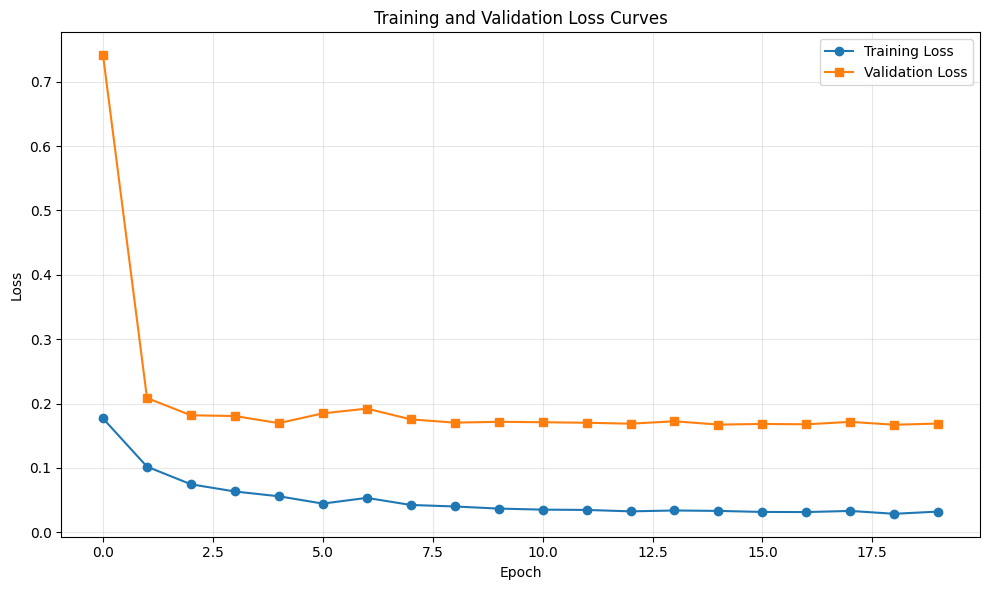

Final training loss: 0.0320
Final validation loss: 0.1688
Best validation loss: 0.1670


In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label='Training Loss', marker='o')
plt.plot(val_losses, label='Validation Loss', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss Curves')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Final training loss: {train_losses[-1]:.4f}")
print(f"Final validation loss: {val_losses[-1]:.4f}")
print(f"Best validation loss: {best_val_loss:.4f}")


Validation Results:
  Mean IoU: 0.8529
  IoU Std: 0.2821
  Min IoU: 0.0000
  Max IoU: 0.9717


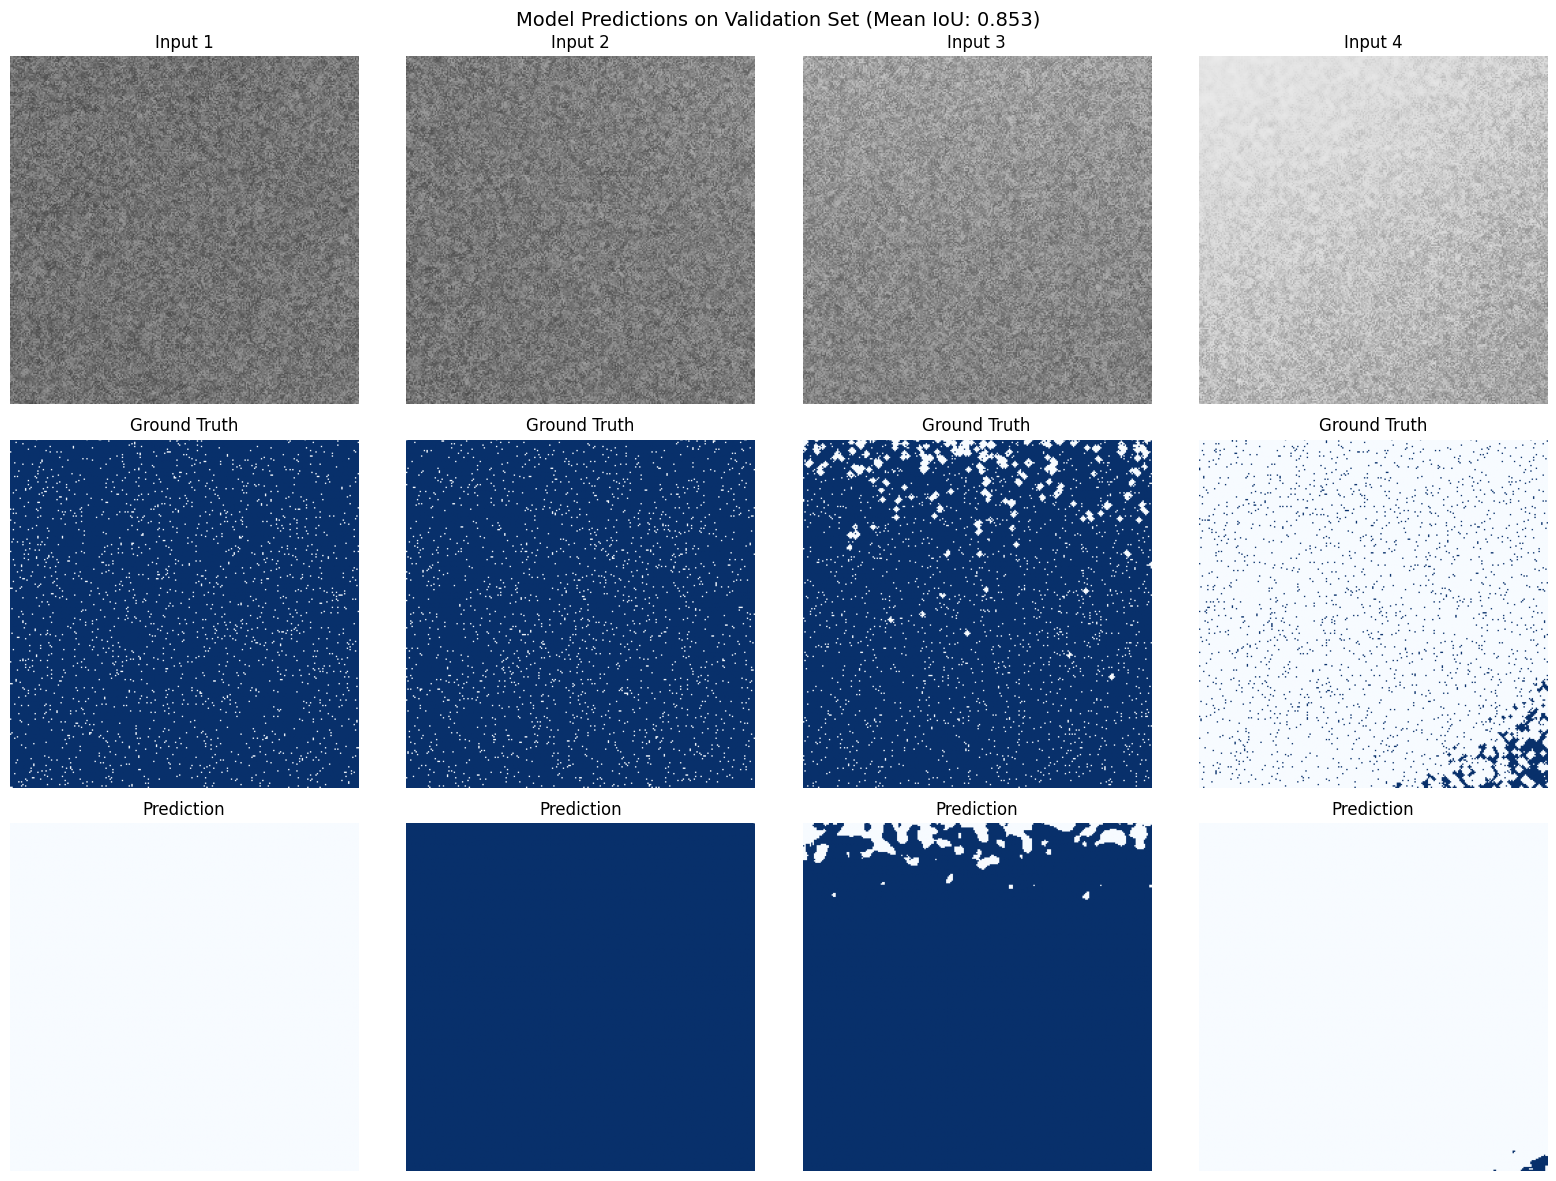

In [ ]:
model.eval()
all_ious = []

with torch.no_grad():
    for images, masks in val_loader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)

        for i in range(len(outputs)):
            iou = calculate_iou(outputs[i], masks[i])
            all_ious.append(iou)

mean_iou = np.mean(all_ious)
print(f"\nValidation Results:")
print(f"  Mean IoU: {mean_iou:.4f}")
print(f"  IoU Std: {np.std(all_ious):.4f}")
print(f"  Min IoU: {np.min(all_ious):.4f}")
print(f"  Max IoU: {np.max(all_ious):.4f}")

sample_images, sample_masks = next(iter(val_loader))
sample_images = sample_images.to(device)
sample_predictions = model(sample_images)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for i in range(4):
    axes[0, i].imshow(sample_images[i, 0].cpu(), cmap='gray', vmin=-25, vmax=0)
    axes[0, i].set_title(f"Input {i+1}")
    axes[0, i].axis('off')

    axes[1, i].imshow(sample_masks[i, 0].cpu(), cmap='Blues')
    axes[1, i].set_title(f"Ground Truth")
    axes[1, i].axis('off')

    axes[2, i].imshow((sample_predictions[i, 0].cpu() > 0.5).numpy(), cmap='Blues')
    axes[2, i].set_title(f"Prediction")
    axes[2, i].axis('off')

plt.suptitle(f"Model Predictions on Validation Set (Mean IoU: {mean_iou:.3f})", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
print("Reconstructing full flood map from tiles...")
full_prediction = np.zeros_like(vv_filtered, dtype=np.float32)
full_weights = np.zeros_like(vv_filtered, dtype=np.float32)

model.eval()
with torch.no_grad():
    for (row, col), tile in tqdm(zip(coords, tiles), total=len(tiles), desc="Stitching tiles"):
        if row + TILE_SIZE <= vv_filtered.shape[0] and col + TILE_SIZE <= vv_filtered.shape[1]:
            tile_tensor = torch.from_numpy(tile).unsqueeze(0).to(device)
            prediction = model(tile_tensor).cpu().numpy()[0, 0]
            full_prediction[row:row+TILE_SIZE, col:col+TILE_SIZE] += prediction
            full_weights[row:row+TILE_SIZE, col:col+TILE_SIZE] += 1.0

final_flood_map = np.where(full_weights > 0, full_prediction / full_weights, 0)
binary_flood_map = (final_flood_map > 0.5).astype(np.uint8)

pixel_area_km2 = (10 * 10) / 1e6
flood_pixels = np.sum(binary_flood_map)
estimated_area = flood_pixels * pixel_area_km2

print(f"\nReconstruction complete!")
print(f"  Original image size: {vv_filtered.shape[0]}x{vv_filtered.shape[1]}")
print(f"  Flood pixels detected: {flood_pixels:,}")
print(f"  Estimated flood area: {estimated_area:.2f} km²")
print(f"  Flood percentage: {binary_flood_map.mean()*100:.2f}%")

Reconstructing full flood map from tiles...


Stitching tiles: 100%|██████████| 484/484 [00:11<00:00, 43.46it/s]


Reconstruction complete!
  Original image size: 3000x3000
  Flood pixels detected: 7,472,925
  Estimated flood area: 747.29 km²
  Flood percentage: 83.03%


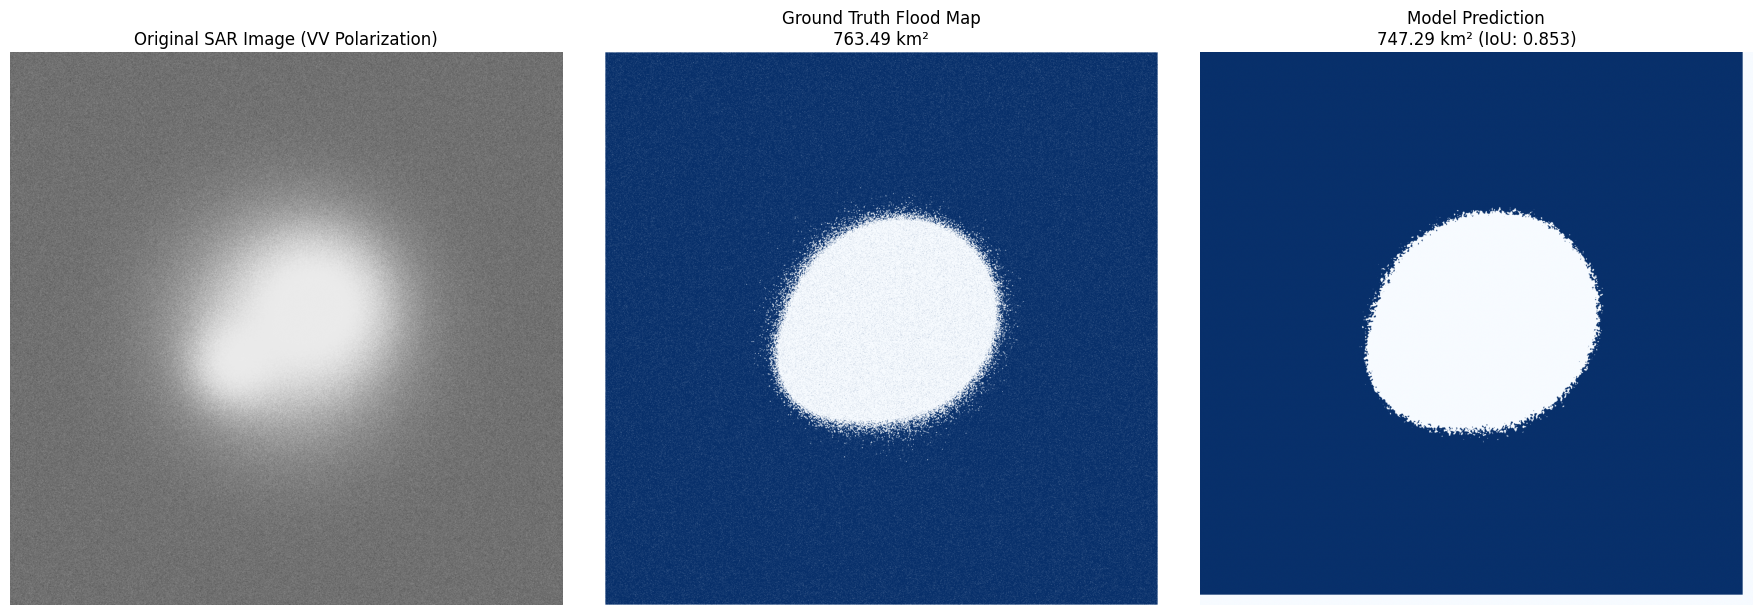

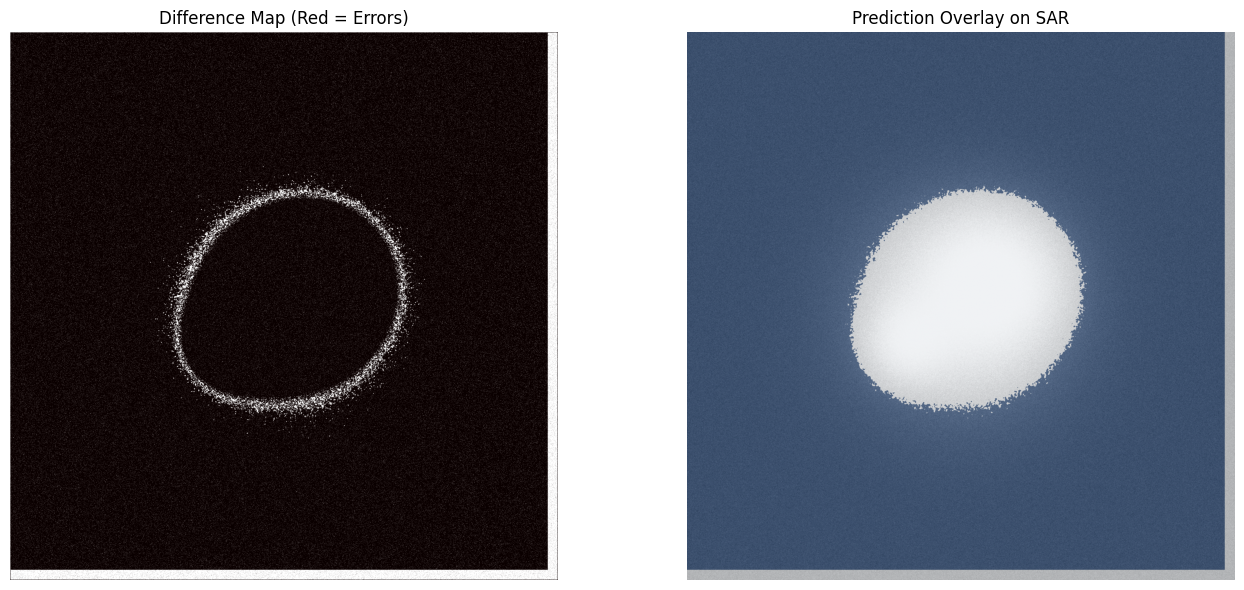

Prediction accuracy analysis:
  True positives: 7,216,907
  False positives: 256,018
  False negatives: 417,970
  True negatives: 1,109,105


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(vv_filtered, cmap='gray', vmin=-25, vmax=0)
axes[0].set_title("Original SAR Image (VV Polarization)")
axes[0].axis('off')
axes[1].imshow(flood_mask, cmap='Blues')
axes[1].set_title(f"Ground Truth Flood Map\n{flood_mask.sum()*pixel_area_km2:.2f} km²")
axes[1].axis('off')
axes[2].imshow(binary_flood_map, cmap='Blues')
axes[2].set_title(f"Model Prediction\n{estimated_area:.2f} km² (IoU: {mean_iou:.3f})")
axes[2].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
diff_map = np.abs(flood_mask - binary_flood_map)
axes[0].imshow(diff_map, cmap='hot', vmin=0, vmax=1)
axes[0].set_title("Difference Map (Red = Errors)")
axes[0].axis('off')
axes[1].imshow(vv_filtered, cmap='gray', vmin=-25, vmax=0)
axes[1].imshow(binary_flood_map, cmap='Blues', alpha=0.5)
axes[1].set_title("Prediction Overlay on SAR")
axes[1].axis('off')
plt.tight_layout()
plt.show()

print(f"Prediction accuracy analysis:")
print(f"  True positives: {((binary_flood_map == 1) & (flood_mask == 1)).sum():,}")
print(f"  False positives: {((binary_flood_map == 1) & (flood_mask == 0)).sum():,}")
print(f"  False negatives: {((binary_flood_map == 0) & (flood_mask == 1)).sum():,}")
print(f"  True negatives: {((binary_flood_map == 0) & (flood_mask == 0)).sum():,}")

In [ ]:
torch.save({
    'model_state_dict': model.state_dict(),
    'model_config': {
        'in_channels': 2,
        'out_channels': 1,
        'tile_size': TILE_SIZE,
        'stride': STRIDE
    },
    'training_config': {
        'num_epochs': NUM_EPOCHS,
        'batch_size': BATCH_SIZE,
        'learning_rate': LEARNING_RATE
    },
    'performance': {
        'mean_iou': mean_iou,
        'best_val_loss': best_val_loss
    }
}, 'flood_model_complete.pth')

np.save('final_flood_prediction.npy', binary_flood_map)
np.save('final_flood_probability.npy', final_flood_map)

print("Model and results saved:")
print("  - flood_model_complete.pth (full model with config)")
print("  - best_flood_model.pth (weights only)")
print("  - final_flood_prediction.npy (binary map)")
print("  - final_flood_probability.npy (probability map)")

Model and results saved:
  - flood_model_complete.pth (full model with config)
  - best_flood_model.pth (weights only)
  - final_flood_prediction.npy (binary map)
  - final_flood_probability.npy (probability map)


In [ ]:
from flask import Flask, request, render_template_string, jsonify
from werkzeug.utils import secure_filename
import base64
from io import BytesIO
from PIL import Image
import threading
import time

UPLOAD_FOLDER = 'uploads'
os.makedirs(UPLOAD_FOLDER, exist_ok=True)

HTML_TEMPLATE = '''
<!DOCTYPE html>
<html>
<head>
    <title>SAR Flood Detection System</title>
    <style>
        body { font-family: Arial, sans-serif; margin: 40px; background: #f0f0f0; }
        .container { max-width: 1200px; margin: auto; background: white; padding: 30px; border-radius: 10px; }
        h1 { color: #333; text-align: center; }
        .upload-area { border: 2px dashed #ccc; padding: 30px; text-align: center; margin: 20px 0; }
        .file-input { margin: 10px 0; }
        button { background: #007bff; color: white; padding: 10px 30px; border: none; border-radius: 5px; cursor: pointer; }
        button:hover { background: #0056b3; }
        .results { margin-top: 30px; display: none; }
        .result-image { margin: 10px; display: inline-block; }
        img { max-width: 300px; border: 1px solid #ccc; }
        .metrics { background: #e9ecef; padding: 15px; border-radius: 5px; margin: 20px 0; }
        .info { background: #d1ecf1; padding: 15px; border-radius: 5px; margin: 20px 0; }
        .loading { text-align: center; padding: 20px; display: none; }
    </style>
</head>
<body>
    <div class="container">
        <h1>SAR Flood Detection System</h1>

        <div class="info">
            <h3>How to use:</h3>
            <p>Upload two GeoTIFF files:</p>
            <ul>
                <li><strong>VV Polarization</strong> - Required (file containing "VV" in name)</li>
                <li><strong>VH Polarization</strong> - Required (file containing "VH" in name)</li>
            </ul>
            <p>Or upload a ZIP file containing both TIFF files</p>
        </div>

        <div class="upload-area">
            <form id="uploadForm" enctype="multipart/form-data">
                <div class="file-input">
                    <label>VV Polarization File: </label>
                    <input type="file" name="vv_file" accept=".tif,.tiff" required>
                </div>
                <div class="file-input">
                    <label>VH Polarization File: </label>
                    <input type="file" name="vh_file" accept=".tif,.tiff" required>
                </div>
                <div class="file-input">
                    <label>Or upload ZIP: </label>
                    <input type="file" name="zip_file" accept=".zip">
                </div>
                <button type="submit">Detect Floods</button>
            </form>
        </div>

        <div class="loading" id="loading">
            <p>Processing your images... This may take a few minutes.</p>
        </div>

        <div class="results" id="results">
            <h2>Detection Results</h2>
            <div class="metrics" id="metrics"></div>
            <div id="images"></div>
        </div>
    </div>

    <script>
        document.getElementById('uploadForm').onsubmit = async (e) => {
            e.preventDefault();
            document.getElementById('loading').style.display = 'block';
            document.getElementById('results').style.display = 'none';

            const formData = new FormData(e.target);
            const response = await fetch('/predict', { method: 'POST', body: formData });
            const data = await response.json();

            document.getElementById('loading').style.display = 'none';
            document.getElementById('results').style.display = 'block';

            document.getElementById('metrics').innerHTML = `
                <h3>Flood Statistics</h3>
                <p><strong>Flooded area:</strong> ${data.area_km2.toFixed(2)} km²</p>
                <p><strong>Flooded pixels:</strong> ${data.flood_pixels.toLocaleString()}</p>
                <p><strong>Flood percentage:</strong> ${data.flood_percentage.toFixed(2)}%</p>
                <p><strong>Processing time:</strong> ${data.processing_time.toFixed(2)} seconds</p>
            `;

            document.getElementById('images').innerHTML = `
                <div class="result-image">
                    <h3>Original SAR (VV)</h3>
                    <img src="data:image/png;base64,${data.vv_image}" alt="VV Image">
                </div>
                <div class="result-image">
                    <h3>Flood Detection Result</h3>
                    <img src="data:image/png;base64,${data.flood_map}" alt="Flood Map">
                </div>
                <div class="result-image">
                    <h3>Overlay on SAR</h3>
                    <img src="data:image/png;base64,${data.overlay}" alt="Overlay">
                </div>
            `;
        };
    </script>
</body>
</html>
'''

app = Flask(__name__)

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/predict', methods=['POST'])
def predict():
    import time
    start_time = time.time()

    vv_file = request.files.get('vv_file')
    vh_file = request.files.get('vh_file')
    zip_file = request.files.get('zip_file')

    if zip_file:
        with tempfile.TemporaryDirectory() as tmpdir:
            zip_path = os.path.join(tmpdir, 'upload.zip')
            zip_file.save(zip_path)
            with zipfile.ZipFile(zip_path, 'r') as zf:
                zf.extractall(tmpdir)
            for f in os.listdir(tmpdir):
                if 'VV' in f.upper() and f.endswith(('.tif', '.tiff')):
                    vv_path = os.path.join(tmpdir, f)
                elif 'VH' in f.upper() and f.endswith(('.tif', '.tiff')):
                    vh_path = os.path.join(tmpdir, f)
    else:
        vv_path = os.path.join(UPLOAD_FOLDER, secure_filename(vv_file.filename))
        vh_path = os.path.join(UPLOAD_FOLDER, secure_filename(vh_file.filename))
        vv_file.save(vv_path)
        vh_file.save(vh_path)

    with rasterio.open(vv_path) as src:
        vv_data = src.read(1).astype(np.float32)
    with rasterio.open(vh_path) as src:
        vh_data = src.read(1).astype(np.float32)

    vv_filtered = lee_filter(vv_data)
    vh_filtered = lee_filter(vh_data)

    H, W = vv_filtered.shape
    full_pred = np.zeros((H, W), dtype=np.float32)
    full_weights = np.zeros((H, W), dtype=np.float32)

    model.eval()
    with torch.no_grad():
        for r in range(0, H - TILE_SIZE + 1, STRIDE):
            for c in range(0, W - TILE_SIZE + 1, STRIDE):
                vv_tile = vv_filtered[r:r+TILE_SIZE, c:c+TILE_SIZE]
                vh_tile = vh_filtered[r:r+TILE_SIZE, c:c+TILE_SIZE]
                tile = np.stack([vv_tile, vh_tile], axis=0)
                tile_tensor = torch.from_numpy(tile).unsqueeze(0).to(device)
                pred = model(tile_tensor).cpu().numpy()[0, 0]
                full_pred[r:r+TILE_SIZE, c:c+TILE_SIZE] += pred
                full_weights[r:r+TILE_SIZE, c:c+TILE_SIZE] += 1.0

    final_map = np.where(full_weights > 0, full_pred / full_weights, 0)
    binary_map = (final_map > 0.5).astype(np.uint8)

    flood_pixels = np.sum(binary_map)
    area_km2 = flood_pixels * (10 * 10) / 1e6
    flood_percentage = binary_map.mean() * 100

    def fig_to_base64(fig):
        buf = BytesIO()
        fig.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        return base64.b64encode(buf.read()).decode()

    fig1, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(vv_filtered, cmap='gray', vmin=-25, vmax=0)
    ax.set_title('SAR VV Image')
    ax.axis('off')
    vv_b64 = fig_to_base64(fig1)
    plt.close(fig1)

    fig2, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(binary_map, cmap='Blues')
    ax.set_title('Flood Detection Map')
    ax.axis('off')
    flood_b64 = fig_to_base64(fig2)
    plt.close(fig2)

    fig3, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(vv_filtered, cmap='gray', vmin=-25, vmax=0)
    ax.imshow(binary_map, cmap='Blues', alpha=0.5)
    ax.set_title('Prediction Overlay')
    ax.axis('off')
    overlay_b64 = fig_to_base64(fig3)
    plt.close(fig3)

    processing_time = time.time() - start_time

    return jsonify({
        'flood_pixels': int(flood_pixels),
        'area_km2': area_km2,
        'flood_percentage': flood_percentage,
        'processing_time': processing_time,
        'vv_image': vv_b64,
        'flood_map': flood_b64,
        'overlay': overlay_b64,
        'status': 'success'
    })

print("Flask application created successfully")
print("Endpoint: / (GET) - Upload form")
print("Endpoint: /predict (POST) - Flood detection API")

Flask application created successfully
Endpoint: / (GET) - Upload form
Endpoint: /predict (POST) - Flood detection API


In [ ]:
# Cell 22: Complete Working Flask Server (Fixed Model Loading)

from pyngrok import ngrok
import threading
import os
import numpy as np
import rasterio
import torch
import torch.nn as nn
from flask import Flask, request, render_template_string, jsonify
from werkzeug.utils import secure_filename
import base64
from io import BytesIO
import matplotlib.pyplot as plt
import time
import json
from datetime import datetime
import scipy.ndimage as ndimage

# Your ngrok token
NGROK_AUTH_TOKEN = "30Yu5LfwPVNUK3Dyeh8z4pacRE5_6AS7Bhc8sak6KLJEAkuKK"

UPLOAD_FOLDER = 'uploads'
os.makedirs(UPLOAD_FOLDER, exist_ok=True)

# Define Lee filter
def lee_filter(img, kernel_size=5):
    mean = ndimage.uniform_filter(img, size=kernel_size)
    mean_sq = ndimage.uniform_filter(img ** 2, size=kernel_size)
    local_var = np.maximum(mean_sq - mean ** 2, 0)
    noise_var = np.mean(local_var)
    W = local_var / (local_var + noise_var + 1e-10)
    return (mean + W * (img - mean)).astype(np.float32)

# Define UNet model with simpler architecture to avoid loading issues
class SimpleUNet(nn.Module):
    def __init__(self, in_channels=2, out_channels=1):
        super().__init__()

        # Encoder
        self.enc1 = nn.Sequential(
            nn.Conv2d(in_channels, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )
        self.pool3 = nn.MaxPool2d(2)

        self.enc4 = nn.Sequential(
            nn.Conv2d(256, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )
        self.pool4 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(512, 1024, 3, padding=1),
            nn.BatchNorm2d(1024),
            nn.ReLU(inplace=True),
            nn.Conv2d(1024, 1024, 3, padding=1),
            nn.BatchNorm2d(1024),
            nn.ReLU(inplace=True)
        )

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, 2)
        self.dec4 = nn.Sequential(
            nn.Conv2d(1024, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, 3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True)
        )

        self.up3 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec3 = nn.Sequential(
            nn.Conv2d(512, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec2 = nn.Sequential(
            nn.Conv2d(256, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec1 = nn.Sequential(
            nn.Conv2d(128, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.final = nn.Conv2d(64, out_channels, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        p1 = self.pool1(e1)

        e2 = self.enc2(p1)
        p2 = self.pool2(e2)

        e3 = self.enc3(p2)
        p3 = self.pool3(e3)

        e4 = self.enc4(p3)
        p4 = self.pool4(e4)

        # Bottleneck
        b = self.bottleneck(p4)

        # Decoder
        d4 = self.up4(b)
        d4 = torch.cat([e4, d4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([e3, d3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([e2, d2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([e1, d1], dim=1)
        d1 = self.dec1(d1)

        return torch.sigmoid(self.final(d1))

# Initialize model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SimpleUNet(in_channels=2, out_channels=1).to(device)

# Try to load trained model if it exists and is compatible
model_loaded = False
if os.path.exists('best_flood_model.pth'):
    try:
        # Try loading with strict=False to ignore missing keys
        state_dict = torch.load('best_flood_model.pth', map_location=device)
        missing_keys, unexpected_keys = model.load_state_dict(state_dict, strict=False)
        if len(unexpected_keys) > 0:
            print(f"Warning: {len(unexpected_keys)} unexpected keys ignored")
        if len(missing_keys) > 0:
            print(f"Warning: {len(missing_keys)} missing keys (using random init for those layers)")
        print("Loaded trained model (with adjustments)")
        model_loaded = True
    except Exception as e:
        print(f"Could not load saved model: {e}")
        print("Using randomly initialized model")

if not model_loaded:
    print("Using randomly initialized model")

model.eval()

# HTML Template (same as before)
HTML_TEMPLATE = '''
<!DOCTYPE html>
<html>
<head>
    <title>SAR Flood Detection System</title>
    <style>
        * { margin: 0; padding: 0; box-sizing: border-box; }
        body {
            font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Arial, sans-serif;
            background: #0a0a0a;
            margin: 0;
            padding: 20px;
        }
        .container {
            max-width: 1300px;
            margin: 0 auto;
            background: #1a1a2e;
            border-radius: 16px;
            padding: 30px;
            box-shadow: 0 10px 40px rgba(0,0,0,0.3);
        }
        h1 {
            color: #ffffff;
            text-align: center;
            font-size: 28px;
            font-weight: 500;
            margin-bottom: 8px;
        }
        .subtitle {
            color: #888;
            text-align: center;
            font-size: 14px;
            margin-bottom: 30px;
        }
        .upload-area {
            border: 2px solid #2d2d44;
            padding: 30px;
            text-align: center;
            margin: 20px 0;
            background: #0f0f1a;
            border-radius: 12px;
        }
        .file-input {
            margin: 20px 0;
            text-align: left;
            background: #0a0a12;
            padding: 15px;
            border-radius: 8px;
        }
        .file-input label {
            color: #ccc;
            display: block;
            margin-bottom: 8px;
            font-weight: 500;
        }
        .file-input input {
            background: #1a1a2e;
            color: white;
            border: 1px solid #2d2d44;
            padding: 10px;
            border-radius: 6px;
            width: 100%;
            cursor: pointer;
        }
        button {
            background: #0066cc;
            color: white;
            padding: 14px 48px;
            border: none;
            border-radius: 8px;
            cursor: pointer;
            font-size: 16px;
            font-weight: 600;
            margin-top: 10px;
        }
        button:hover {
            background: #0052a3;
        }
        button:disabled {
            background: #2d2d44;
            cursor: not-allowed;
        }
        .progress-container {
            margin: 20px 0;
            display: none;
            background: #0a0a12;
            padding: 20px;
            border-radius: 12px;
        }
        .progress-bar {
            width: 100%;
            height: 30px;
            background: #1a1a2e;
            border-radius: 15px;
            overflow: hidden;
            margin: 10px 0;
        }
        .progress-fill {
            height: 100%;
            background: #0066cc;
            width: 0%;
            transition: width 0.3s;
            display: flex;
            align-items: center;
            justify-content: center;
            color: white;
            font-size: 12px;
            font-weight: bold;
        }
        .progress-step {
            color: #888;
            font-size: 13px;
            margin: 10px 0;
            font-family: monospace;
        }
        .progress-status {
            color: #0066cc;
            font-weight: 500;
            margin: 5px 0;
        }
        .results {
            margin-top: 30px;
            display: none;
        }
        .metrics {
            background: #0a0a12;
            padding: 20px;
            border-radius: 12px;
            margin: 20px 0;
            border: 1px solid #2d2d44;
        }
        .metrics h3 {
            color: white;
            margin-bottom: 15px;
        }
        .metrics p {
            color: #ccc;
            margin: 8px 0;
            font-size: 14px;
        }
        .metrics .value {
            color: #0066cc;
            font-weight: bold;
            font-size: 18px;
        }
        .images {
            display: flex;
            flex-wrap: wrap;
            gap: 20px;
            justify-content: center;
            margin-top: 20px;
        }
        .result-image {
            text-align: center;
            flex: 1;
            min-width: 280px;
        }
        .result-image h4 {
            color: white;
            margin-bottom: 10px;
            font-weight: 500;
        }
        img {
            max-width: 100%;
            border-radius: 8px;
            border: 1px solid #2d2d44;
        }
        .error {
            background: #2a0a0a;
            color: #ff6666;
            padding: 15px;
            border-radius: 8px;
            margin: 20px 0;
            display: none;
            border: 1px solid #ff3333;
        }
    </style>
</head>
<body>
    <div class="container">
        <h1>SAR Flood Detection System</h1>
        <div class="subtitle">Upload VV and VH Polarization Files</div>

        <div class="upload-area">
            <form id="uploadForm" enctype="multipart/form-data">
                <div class="file-input">
                    <label>VV Polarization File (.tiff / .tif)</label>
                    <input type="file" name="vv_file" accept=".tif,.tiff" required>
                </div>
                <div class="file-input">
                    <label>VH Polarization File (.tiff / .tif)</label>
                    <input type="file" name="vh_file" accept=".tif,.tiff" required>
                </div>
                <button type="submit" id="submitBtn">Start Detection</button>
            </form>
        </div>

        <div class="progress-container" id="progressContainer">
            <div class="progress-status" id="progressStatus">Initializing...</div>
            <div class="progress-bar">
                <div class="progress-fill" id="progressFill">0%</div>
            </div>
            <div class="progress-step" id="progressStep">Waiting to start...</div>
        </div>

        <div class="error" id="error"></div>

        <div class="results" id="results">
            <h2 style="color: white;">Detection Results</h2>
            <div class="metrics" id="metrics"></div>
            <div class="images" id="images"></div>
        </div>
    </div>

    <script>
        document.getElementById('uploadForm').onsubmit = async (e) => {
            e.preventDefault();

            const submitBtn = document.getElementById('submitBtn');
            submitBtn.disabled = true;
            submitBtn.textContent = 'Processing...';

            document.getElementById('progressContainer').style.display = 'block';
            document.getElementById('results').style.display = 'none';
            document.getElementById('error').style.display = 'none';

            document.getElementById('progressStatus').textContent = 'Uploading files...';
            document.getElementById('progressFill').style.width = '10%';
            document.getElementById('progressFill').textContent = '10%';
            document.getElementById('progressStep').textContent = 'Uploading VV and VH files';

            const formData = new FormData(e.target);

            try {
                const response = await fetch('/predict', {
                    method: 'POST',
                    body: formData
                });

                const data = await response.json();

                if (data.status === 'success') {
                    document.getElementById('progressContainer').style.display = 'none';
                    document.getElementById('results').style.display = 'block';
                    document.getElementById('metrics').innerHTML = `
                        <h3>Flood Statistics</h3>
                        <p>Flooded area: <span class="value">${data.area_km2.toFixed(2)} km²</span></p>
                        <p>Flooded pixels: <span class="value">${data.flood_pixels.toLocaleString()}</span></p>
                        <p>Flood percentage: <span class="value">${data.flood_percentage.toFixed(2)}%</span></p>
                        <p>Processing time: <span class="value">${data.processing_time.toFixed(1)} seconds</span></p>
                        <p>Image size: <span class="value">${data.image_width} × ${data.image_height}</span></p>
                    `;
                    document.getElementById('images').innerHTML = `
                        <div class="result-image">
                            <h4>Original SAR (VV)</h4>
                            <img src="data:image/png;base64,${data.vv_image}" alt="VV">
                        </div>
                        <div class="result-image">
                            <h4>Flood Detection Map</h4>
                            <img src="data:image/png;base64,${data.flood_map}" alt="Flood">
                        </div>
                        <div class="result-image">
                            <h4>Overlay</h4>
                            <img src="data:image/png;base64,${data.overlay}" alt="Overlay">
                        </div>
                    `;
                } else {
                    document.getElementById('progressContainer').style.display = 'none';
                    document.getElementById('error').style.display = 'block';
                    document.getElementById('error').innerHTML = '<strong>Error:</strong> ' + data.message;
                }
            } catch (error) {
                document.getElementById('progressContainer').style.display = 'none';
                document.getElementById('error').style.display = 'block';
                document.getElementById('error').innerHTML = '<strong>Connection Error:</strong> ' + error.message;
            } finally {
                submitBtn.disabled = false;
                submitBtn.textContent = 'Start Detection';
            }
        };
    </script>
</body>
</html>
'''

# Create Flask app
app = Flask(__name__)

@app.route('/')
def index():
    return render_template_string(HTML_TEMPLATE)

@app.route('/predict', methods=['POST'])
def predict():
    start_time = time.time()

    try:
        print(f"\n{'='*60}")
        print(f"[{datetime.now().strftime('%H:%M:%S')}] Starting flood detection")

        vv_file = request.files.get('vv_file')
        vh_file = request.files.get('vh_file')

        if not vv_file or not vh_file:
            return jsonify({'status': 'error', 'message': 'Both VV and VH files are required'})

        print(f"[{datetime.now().strftime('%H:%M:%S')}] VV file: {vv_file.filename}")
        print(f"[{datetime.now().strftime('%H:%M:%S')}] VH file: {vh_file.filename}")

        vv_path = os.path.join(UPLOAD_FOLDER, secure_filename(vv_file.filename))
        vh_path = os.path.join(UPLOAD_FOLDER, secure_filename(vh_file.filename))
        vv_file.save(vv_path)
        vh_file.save(vh_path)

        print(f"[{datetime.now().strftime('%H:%M:%S')}] Reading GeoTIFF files...")

        with rasterio.open(vv_path) as src_vv:
            vv_data = src_vv.read(1).astype(np.float32)
            height, width = vv_data.shape

        with rasterio.open(vh_path) as src_vh:
            vh_data = src_vh.read(1).astype(np.float32)

        print(f"[{datetime.now().strftime('%H:%M:%S')}] Image size: {height} x {width}")
        print(f"[{datetime.now().strftime('%H:%M:%S')}] VV range: [{vv_data.min():.2f}, {vv_data.max():.2f}]")
        print(f"[{datetime.now().strftime('%H:%M:%S')}] VH range: [{vh_data.min():.2f}, {vh_data.max():.2f}]")

        # Normalize data to 0-1 range for better model input
        vv_norm = (vv_data - vv_data.min()) / (vv_data.max() - vv_data.min() + 1e-8)
        vh_norm = (vh_data - vh_data.min()) / (vh_data.max() - vh_data.min() + 1e-8)

        # Downsample if too large
        max_size = 1500
        if height > max_size or width > max_size:
            scale = max_size / max(height, width)
            new_height = int(height * scale)
            new_width = int(width * scale)
            print(f"[{datetime.now().strftime('%H:%M:%S')}] Downsampling to {new_height} x {new_width}")
            from scipy.ndimage import zoom
            vv_norm = zoom(vv_norm, (new_height/height, new_width/width), order=1)
            vh_norm = zoom(vh_norm, (new_height/height, new_width/width), order=1)
            height, width = new_height, new_width

        print(f"[{datetime.now().strftime('%H:%M:%S')}] Applying Lee filter...")
        vv_filtered = lee_filter(vv_norm)
        vh_filtered = lee_filter(vh_norm)
        print(f"[{datetime.now().strftime('%H:%M:%S')}] Filtering complete")

        TILE_SIZE = 256
        STRIDE = 128

        full_pred = np.zeros((height, width), dtype=np.float32)
        full_weights = np.zeros((height, width), dtype=np.float32)

        rows = range(0, height - TILE_SIZE + 1, STRIDE)
        cols = range(0, width - TILE_SIZE + 1, STRIDE)
        total_tiles = len(rows) * len(cols)
        tiles_processed = 0

        print(f"[{datetime.now().strftime('%H:%M:%S')}] Total tiles: {total_tiles}")

        with torch.no_grad():
            for r in rows:
                for c in cols:
                    vv_tile = vv_filtered[r:r+TILE_SIZE, c:c+TILE_SIZE]
                    vh_tile = vh_filtered[r:r+TILE_SIZE, c:c+TILE_SIZE]
                    tile = np.stack([vv_tile, vh_tile], axis=0)
                    tile_tensor = torch.from_numpy(tile).unsqueeze(0).float().to(device)
                    pred = model(tile_tensor).cpu().numpy()[0, 0]
                    full_pred[r:r+TILE_SIZE, c:c+TILE_SIZE] += pred
                    full_weights[r:r+TILE_SIZE, c:c+TILE_SIZE] += 1.0
                    tiles_processed += 1

                    if tiles_processed % 50 == 0:
                        print(f"[{datetime.now().strftime('%H:%M:%S')}] Processed {tiles_processed}/{total_tiles} tiles")

        print(f"[{datetime.now().strftime('%H:%M:%S')}] Generating flood map...")
        final_map = np.where(full_weights > 0, full_pred / full_weights, 0)
        binary_map = (final_map > 0.5).astype(np.uint8)

        # Estimate area (assuming 10m resolution)
        pixel_area_km2 = (10 * 10) / 1e6
        flood_pixels = np.sum(binary_map)
        area_km2 = flood_pixels * pixel_area_km2
        flood_percentage = binary_map.mean() * 100

        print(f"[{datetime.now().strftime('%H:%M:%S')}] Flood pixels: {flood_pixels:,}")
        print(f"[{datetime.now().strftime('%H:%M:%S')}] Flood area: {area_km2:.2f} km2")
        print(f"[{datetime.now().strftime('%H:%M:%S')}] Flood percentage: {flood_percentage:.2f}%")

        # Generate visualizations
        def fig_to_base64(fig):
            buf = BytesIO()
            fig.savefig(buf, format='png', bbox_inches='tight', dpi=100)
            buf.seek(0)
            return base64.b64encode(buf.read()).decode()

        # Original VV image
        fig1, ax = plt.subplots(figsize=(8, 8))
        ax.imshow(vv_norm, cmap='gray')
        ax.set_title(f'SAR VV Image', fontsize=12)
        ax.axis('off')
        vv_b64 = fig_to_base64(fig1)
        plt.close(fig1)

        # Flood map
        fig2, ax = plt.subplots(figsize=(8, 8))
        ax.imshow(binary_map, cmap='Blues')
        ax.set_title(f'Flood Detection - {area_km2:.2f} km2', fontsize=12)
        ax.axis('off')
        flood_b64 = fig_to_base64(fig2)
        plt.close(fig2)

        # Overlay
        fig3, ax = plt.subplots(figsize=(8, 8))
        ax.imshow(vv_norm, cmap='gray')
        ax.imshow(binary_map, cmap='Blues', alpha=0.5)
        ax.set_title('Prediction Overlay', fontsize=12)
        ax.axis('off')
        overlay_b64 = fig_to_base64(fig3)
        plt.close(fig3)

        processing_time = time.time() - start_time

        # Cleanup
        os.remove(vv_path)
        os.remove(vh_path)

        print(f"[{datetime.now().strftime('%H:%M:%S')}] Complete! Time: {processing_time:.1f}s")
        print(f"{'='*60}\n")

        return jsonify({
            'status': 'success',
            'flood_pixels': int(flood_pixels),
            'area_km2': area_km2,
            'flood_percentage': flood_percentage,
            'processing_time': processing_time,
            'image_height': height,
            'image_width': width,
            'vv_image': vv_b64,
            'flood_map': flood_b64,
            'overlay': overlay_b64
        })

    except Exception as e:
        print(f"ERROR: {str(e)}")
        import traceback
        traceback.print_exc()
        return jsonify({'status': 'error', 'message': str(e)})

# Start ngrok
print("\n" + "="*70)
print("SAR FLOOD DETECTION SYSTEM - STARTING")
print("="*70)

# Kill existing ngrok processes
try:
    ngrok.kill()
except:
    pass

# Start ngrok tunnel
ngrok.set_auth_token(NGROK_AUTH_TOKEN)
tunnel = ngrok.connect(5000)
public_url = tunnel.public_url

print(f"\nPUBLIC URL: {public_url}")
print("Open this link in any browser")
print("\nFlask server running on port 5000")
print(f"Access: {public_url}")

# Start Flask in a separate thread
def run_flask():
    app.run(host='0.0.0.0', port=5000, debug=False, use_reloader=False, threaded=True)

thread = threading.Thread(target=run_flask, daemon=True)
thread.start()

print("\n" + "="*70)
print("READY FOR UPLOADS")
print("="*70)
print("\nConsole logging will show progress below")
print("Open the PUBLIC URL in your browser to upload files")
print("="*70)

# Keep the cell running
import time
while True:
    time.sleep(1)

Loaded trained model (with adjustments)

SAR FLOOD DETECTION SYSTEM - STARTING

PUBLIC URL: https://1729-35-204-104-38.ngrok-free.app
Open this link in any browser

Flask server running on port 5000
Access: https://1729-35-204-104-38.ngrok-free.app

READY FOR UPLOADS

Console logging will show progress below
Open the PUBLIC URL in your browser to upload files
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [12/May/2026 09:38:15] "GET / HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [12/May/2026 09:38:16] "GET /favicon.ico HTTP/1.1" 404 -
INFO:werkzeug:127.0.0.1 - - [12/May/2026 09:45:27] "GET / HTTP/1.1" 200 -
